In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# LED + camera intensity fluctuations

How steady is the illumination, as each scope's camera sees it? This notebook measures the noise, drift,
fluctuation timescales and disturbances of the per-frame mean intensity over a 16 h run, on every scope.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: [`scripts/longterm/intensity_continuous.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/longterm/intensity_continuous.py).
The red LED is held at a fixed control voltage and the camera records continuously at 25 fps. Frames are
encoded and discarded; only the mean of each colour channel is kept, per frame. The LED driver is PWM at
3 MHz, so the PWM itself averages out within each 18 ms exposure. The trap should be empty.

**Running in Colab.** Open this notebook with the *Open in Colab* button on its page. The next cell runs only
in Colab: it installs what Colab lacks and asks for a `.zip` of your experiment folders.

In [ ]:
import os, subprocess, sys
if "google.colab" in sys.modules:                         # skipped everywhere else
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "allantools",
                    "trappy-explorer @ git+https://github.com/Trappy-Scopes/trappy-explorer.git"], check=True)
    from google.colab import files
    for name in files.upload():                           # a .zip of your experiment folders
        subprocess.run(["unzip", "-q", "-o", name, "-d", "/content/data"], check=True)
    root = "/content/data"
    while True:                                           # step into a single wrapping folder
        subs = [d for d in os.listdir(root) if not d.startswith(("__MACOSX", "."))]
        if len(subs) == 1 and not os.path.exists(os.path.join(root, subs[0], "experiment.yaml")):
            root = os.path.join(root, subs[0])
        else:
            break
    os.environ["CALIBRATION_DATA"] = root

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import allantools, rich, yaml
from scipy import signal, optimize, ndimage
from explorer.legacy import ExpExplorer

DATA = os.environ.get("CALIBRATION_DATA", "/Users/byatharth/data/debugging/2026_11_09")   # set to your own runs
OUT = "results"                                        # the fleet table is written here
TZ = "Europe/Lisbon"                                   # where the runs were recorded
FPS = 25.0
SETTLE_MIN = 30                                        # warm-up left out of the statistics
SCOPES = [f"M{i}" for i in range(1, 9)]
COLORS = dict(zip(SCOPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                           "#e87ba4", "#008300", "#6250d6", "#e34948"]))
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.color": "#e8e8e6",
                                 "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                                 "lines.linewidth": 1.2, "legend.frameon": False})

## Data

Runs are read with trappy-explorer's legacy reader, `explorer.legacy.ExpExplorer`. Extended parsing keeps
tuple attributes such as the LED voltages. M1–M4 saved no run attributes.

In [3]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = ExpExplorer.create_superset(DATA, extended_parse=True)
rich.get_console().quiet = False
print(exps)

ms = exps.df_events.query("type == 'measurement_stream'")
res = exps.df.assign(stream=exps.df.measureid.map(dict(zip(ms.measureid, ms.name))))

runs = pd.DataFrame([{"scope": d["metadata"]["name"].split("__")[0], "eid": eid,
                      "started": d["metadata"]["created"],
                      **{k: d["metadata"].get("attribs", {}).get(k)
                         for k in ("run_hours", "fps", "exposure_ms", "light")}}
                     for eid, d in exps.data.items()]).set_index("scope").sort_index()
rows = res.groupby(["eid", "stream"]).size().unstack(fill_value=0)
runs = runs.join(rows.reindex(columns=["tandh", "intensity", "stalls"], fill_value=0), on="eid")
runs

<Experiments :: 8  datasets [extended_parse]>
  |- eid: 7bf3efeea8
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls
  |- eid: d794c6fc7a
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls
  |- eid: a227253e5d
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls
  |- eid: 4231d6c2d5
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls
  |- eid: 9341ba14b4
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls
  |- eid: 54f25f62bc
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls
  |- eid: 15644047a0
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls
  |- eid: 2aa777b229
  	|- m-stream: tandh
  	|- m-stream: intensity
  	|- m-stream: stalls



,eid,started,run_hours,fps,exposure_ms,light,tandh,intensity,stalls
scope,,,,,,,,,
M1,2aa777b229,2026-11-09 15:40:27.557784,NaN,NaN,NaN,None,204,1,0
M2,9341ba14b4,2026-11-09 15:40:40.945630,NaN,NaN,NaN,None,204,1,0
M3,54f25f62bc,2026-11-09 15:41:03.515544,NaN,NaN,NaN,None,204,1,0
M4,d794c6fc7a,2026-11-09 15:41:22.105185,NaN,NaN,NaN,None,204,1,0
M5,a227253e5d,2026-11-09 15:29:32.208622,16.0,25.0,18.0,"(0.5, 0, 0)",205,2,0
M6,4231d6c2d5,2026-11-09 15:29:59.986790,16.0,25.0,18.0,"(0.5, 0, 0)",204,1,0
M7,7bf3efeea8,2026-11-09 15:30:21.159344,16.0,25.0,18.0,"(0.5, 0, 0)",204,1,0
M8,15644047a0,2026-11-09 15:30:43.777629,16.0,25.0,18.0,"(0.5, 0, 0)",204,1,0


In [4]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exps.data[eid]["filetree"]["."]
print(os.path.basename(exps.get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:10s} {len(g):5d} rows   {', '.join(cols)}")

notes = exps.df_events.query("type == 'user_note'")
notes.assign(scope=notes.eid.map(runs.reset_index().set_index("eid").scope))[["scope", "dt", "note"]]

M1__YB__2026_11_09__15hh_40mm__longterm_intensity__2aa777b229
    2aa777b229_intensities.csv
    2aa777b229_telemetry.csv
    experiment.yaml
    logs.yaml
    sessions.yaml
    analysis/
    converted/
    postprocess/
    protocols/
    scripts/

intensity      9 rows   b_mean, b_std, frames, g_mean, g_std, r_mean, r_std, window
tandh       1633 rows   humidity, temp


,scope,dt,note
20,M4,2026-11-09 15:45:21.021981,Device placemnt is off-center.
32,M5,2026-11-09 15:32:00.930255,Empty trap in focus. First microscope will sta...
35,M5,2026-11-09 15:33:41.480017,Mark shaking doesnt work because of the blocki...
91,M1,2026-11-09 15:42:48.575864,Cells loaded with Camila's multitrap devices.
94,M1,2026-11-10 13:46:20.816284,"exp closed midway, next day. All other scopes ..."


Each run folder also holds the two files the analysis uses: `<eid>_intensities.csv` (`t_ns, r, g, b`, one row
per frame; `t_ns` is the camera's sensor timestamp) and `<eid>_telemetry.csv` (one row per second, with the wall
clock and the encoder's frame count, used here to put camera time on the wall clock).

In [5]:
def load(eid):
    d = exps.get_parent_dir(eid)
    x = pd.read_csv(f"{d}/{eid}_intensities.csv", engine="pyarrow")
    x = x.sort_values("t_ns").drop_duplicates("t_ns").reset_index(drop=True)
    tel = pd.read_csv(f"{d}/{eid}_telemetry.csv")
    k = tel.sink_frames.clip(1, len(x)).astype(int) - 1   # newest frame at each telemetry row
    offset = np.median(tel.wall - x.t_ns.to_numpy()[k] / 1e9)
    x = x.iloc[1:]                                       # the first frame precedes the settled light
    x["wall"] = (pd.to_datetime(x.t_ns / 1e9 + offset, unit="s", utc=True)
                 .dt.tz_convert(TZ).dt.tz_localize(None))
    return x

I = {s: load(runs.loc[s, "eid"]) for s in runs.index}
S = {s: I[s][I[s].wall >= I[s].wall.iloc[0] + pd.Timedelta(minutes=SETTLE_MIN)] for s in SCOPES}
tandh = (res.query("stream == 'tandh'")
         .assign(scope=lambda d: d.eid.map(runs.reset_index().set_index("eid").scope),
                 wall=lambda d: pd.to_datetime(d.dt))
         [["scope", "wall", "temp", "humidity"]].sort_values(["scope", "wall"]))
pd.Series({s: len(x) for s, x in I.items()}, name="frames").to_frame().T

,M1,M2,M3,M4,M5,M6,M7,M8
frames,1440176,1440183,1440170,1440184,1440183,1440187,1440181,1440189


## Overview

Each panel is one scope's red intensity, averaged over 1 min and shown as % from its own median. The bottom
panels show the temperature at the scopes in each column (M1–M4 left, M5–M8 right), so drift can be compared
with temperature by eye. In this run M1 and M7 ran under different conditions from the rest; M1 had cells
loaded in its trap and sits at a different focal position.

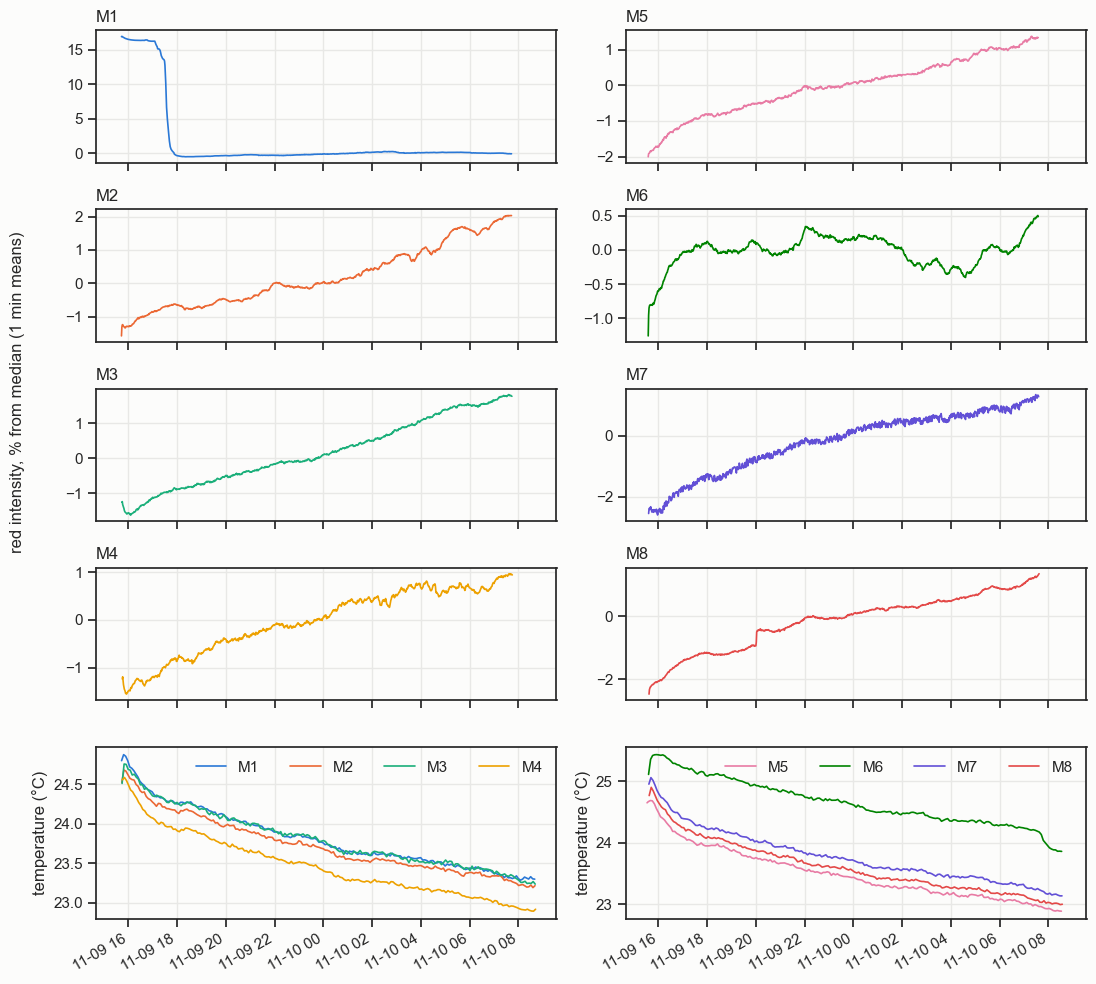

In [6]:
fig, axes = plt.subplots(5, 2, figsize=(11, 10), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 1, 1, 1.3]})
for i, s in enumerate(SCOPES):                            # M1-M4 left, M5-M8 right
    ax, temp = axes[i % 4, i // 4], axes[4, i // 4]
    m = I[s].set_index("wall").r.resample("1min").mean()
    ax.plot(m.index, 100 * (m / m.median() - 1), color=COLORS[s])
    ax.set_title(s, loc="left")
    g = tandh[tandh.scope == s]
    temp.plot(g.wall, g.temp, color=COLORS[s], label=s)
for temp in axes[4]:
    temp.set_ylabel("temperature (°C)")
    temp.legend(ncol=4)
fig.text(0.005, 0.6, "red intensity, % from median (1 min means)", rotation=90, va="center")
fig.autofmt_xdate()
fig.tight_layout(rect=(0.02, 0, 1, 1))

## Noise

`floor_pct` is the frame-to-frame noise, std(Δr)/√2, which drift does not affect. `g_dark` and `b_dark` are the
green and blue channels under red light: crosstalk and dark level. From here on, the first 30 min of each run
are left out.

In [7]:
def noise(x):
    r = x.r.to_numpy(float)
    return pd.Series({"r_mean": r.mean(),
                      "cv_pct": 100 * r.std() / r.mean(),
                      "floor_pct": 100 * np.diff(r).std() / np.sqrt(2) / r.mean(),
                      "g_dark": x.g.mean(), "b_dark": x.b.mean()})

noise_tab = pd.DataFrame({s: noise(S[s]) for s in SCOPES}).T
noise_tab.round(3)

,r_mean,cv_pct,floor_pct,g_dark,b_dark
M1,178.990,4.393,0.008,0.450,0.312
M2,93.642,0.870,0.013,0.049,0.018
M3,70.743,0.912,0.019,0.075,0.036
M4,65.745,0.633,0.045,0.041,0.016
M5,87.881,0.719,0.025,0.047,0.018
M6,79.351,0.188,0.025,0.045,0.017
M7,76.954,0.994,0.333,0.044,0.017
M8,69.345,0.808,0.041,0.039,0.014


The spread of the change between consecutive frames, on a log scale. A narrow peak means low frame-to-frame
noise; wide shoulders mean the intensity often jumps from one frame to the next.

[(-1.0, 1.0),
 (0.001, 38.39376030587029),
 Text(0.5, 0, 'frame-to-frame change in red intensity (%)'),
 None]

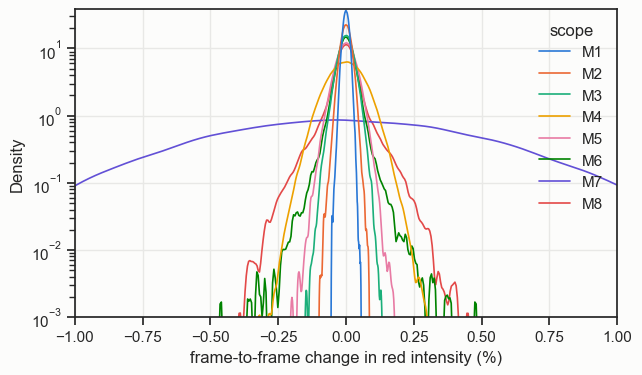

In [8]:
d = pd.concat([pd.DataFrame({"scope": s, "dr_pct": 100 * np.diff(x.r.to_numpy(float)) / x.r.mean()})
               for s, x in S.items()])
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=d.sample(400_000, random_state=0), x="dr_pct", hue="scope", hue_order=SCOPES,
            palette=COLORS, common_norm=False, ax=ax)
ax.set(xlim=(-1, 1), ylim=(1e-3, None), xlabel="frame-to-frame change in red intensity (%)", yscale="log")

## Drift

`tempco_pct_per_C` is the change in red intensity per °C of temperature at the scope, from 5 min means.
Over one night both fall or rise slowly, so a high correlation is expected whatever the cause; a deliberate
temperature step would test it.

In [9]:
def drift(s):
    m = S[s].set_index("wall").r.resample("5min").mean().dropna()
    h = (m.index - m.index[0]).total_seconds() / 3600
    t = tandh[tandh.scope == s].set_index("wall").temp.resample("5min").mean()
    j = pd.concat([100 * (m / m.mean() - 1), t], axis=1, keys=["r_pct", "temp"]).dropna()
    return pd.Series({"drift_pct_per_h": 100 * np.polyfit(h, m, 1)[0] / m.mean(),
                      "last_vs_first_h_pct": 100 * (m[h >= h.max() - 1].mean() / m[h < 1].mean() - 1),
                      "tempco_pct_per_C": np.polyfit(j.temp, j.r_pct, 1)[0],
                      "corr_with_temp": j.r_pct.corr(j.temp)})

drift_tab = pd.DataFrame({s: drift(s) for s in SCOPES}).T
drift_tab.round(3)

,drift_pct_per_h,last_vs_first_h_pct,tempco_pct_per_C,corr_with_temp
M1,-0.472,-14.048,7.717,0.572
M2,0.190,2.889,-2.553,-0.922
M3,0.203,3.063,-2.752,-0.971
M4,0.137,2.132,-1.821,-0.990
M5,0.159,2.580,-1.967,-0.982
M6,0.002,0.518,-0.060,-0.105
M7,0.201,3.263,-2.538,-0.996
M8,0.177,2.843,-2.166,-0.990


## Temperature removed

Red intensity is fitted against the temperature at the scope (5 min means) and the fitted part is subtracted.
If the drift is mostly temperature, the corrected curve (colour) is flat compared with the measured one (grey).
Over one night anything else that changes steadily is removed with it. Runs from 2026-11-13 on also record the
camera-sensor and CPU temperatures (`cam_temp_c`, `temp_c` in the telemetry), which can be used the same way.

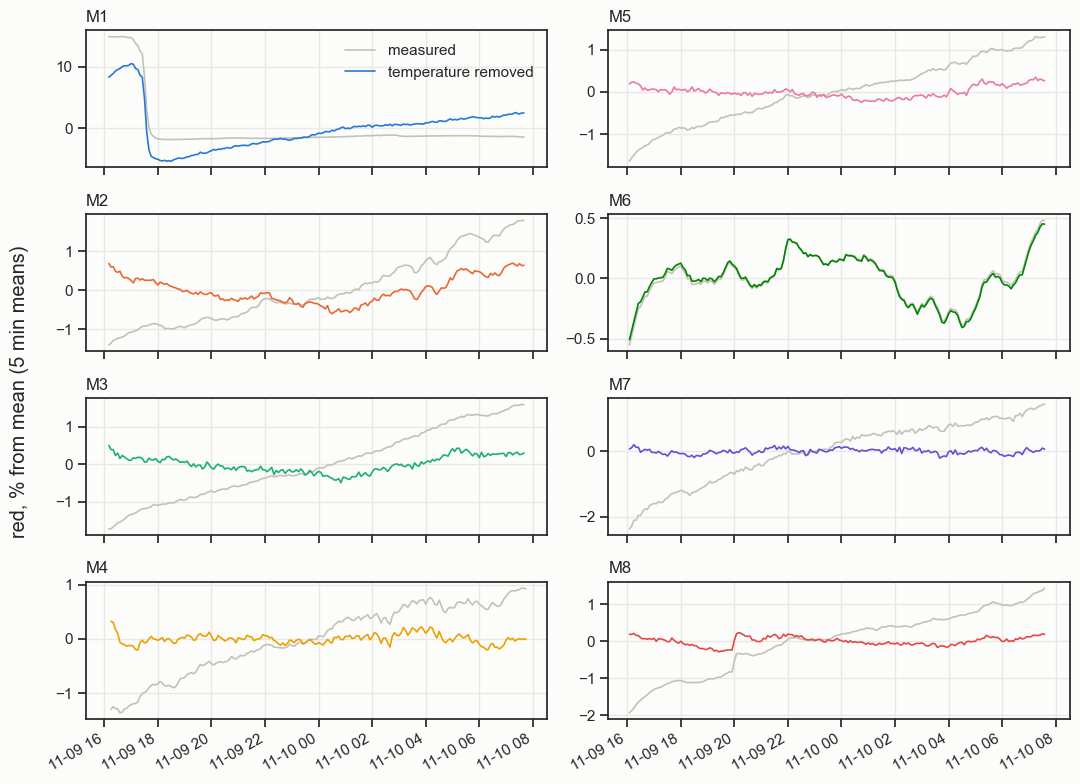

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(11, 8), sharex=True)
temp_tab = {}
for i, s in enumerate(SCOPES):                            # M1-M4 left, M5-M8 right
    ax = axes[i % 4, i // 4]
    m = S[s].set_index("wall").r.resample("5min").mean()
    t = tandh[tandh.scope == s].set_index("wall").temp.resample("5min").mean()
    j = pd.concat([100 * (m / m.mean() - 1), t], axis=1, keys=["r", "T"]).dropna()
    k, b = np.polyfit(j["T"], j.r, 1)
    j["corrected"] = j.r - (k * j["T"] + b)
    ax.plot(j.index, j.r, color="#c3c2b7", label="measured")
    ax.plot(j.index, j.corrected, color=COLORS[s], label="temperature removed")
    ax.set_title(s, loc="left")
    h = (j.index - j.index[0]).total_seconds() / 3600
    temp_tab[s] = {"std_5min_pct": j.r.std(), "std_5min_corrected_pct": j.corrected.std(),
                   "drift_corrected_pct_per_h": np.polyfit(h, j.corrected, 1)[0]}
axes[0, 0].legend(loc="upper right")
fig.supylabel("red, % from mean (5 min means)")
fig.autofmt_xdate()
fig.tight_layout()
temp_tab = pd.DataFrame(temp_tab).T

In [11]:
temp_tab.round(3)

,std_5min_pct,std_5min_corrected_pct,drift_corrected_pct_per_h
M1,4.487,3.680,0.085
M2,0.877,0.340,0.015
M3,0.922,0.219,0.008
M4,0.634,0.091,0.000
M5,0.725,0.135,0.005
M6,0.189,0.188,-0.003
M7,0.934,0.081,0.000
M8,0.816,0.116,0.002


## Timescales

**Power spectrum.** How the fluctuation power is spread over frequency. Each spectrum is fitted with
`A·f^(−α) + B`: a 1/f-type part (α ≈ 1 is flicker noise) and a white floor `B`. The corner frequency is where
the two are equal. Sharp lines above the fitted curve are periodic disturbances.

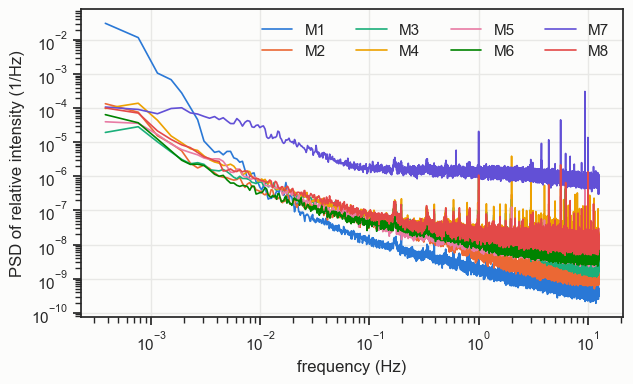

In [12]:
def model(f, logA, alpha, logB):
    return np.log10(10.0**logA * f**-alpha + 10.0**logB)

psd, fits = {}, {}
fig, ax = plt.subplots(figsize=(7, 4))
for s in SCOPES:
    r = S[s].r.to_numpy(float)
    f, p = signal.welch(r / r.mean() - 1, fs=FPS, nperseg=2**16, detrend="linear")
    f, p = f[1:], p[1:]
    b = np.digitize(f, np.logspace(np.log10(f[0]), np.log10(f[-1]), 41))   # log bins, median
    fb, pb = (pd.DataFrame({"f": f, "p": p, "b": b}).groupby("b").median()[c] for c in ("f", "p"))
    (logA, alpha, logB), _ = optimize.curve_fit(model, fb, np.log10(pb), p0=(-8.0, 1.0, -8.0))
    psd[s], fits[s] = (f, p), (logA, alpha, logB)
    ax.loglog(f, p, color=COLORS[s], label=s)
ax.set(xlabel="frequency (Hz)", ylabel="PSD of relative intensity (1/Hz)")
ax.legend(ncol=4)

Each scope's spectrum with the fitted model (dashed). Where the dashed line flattens is the corner frequency;
narrow peaks standing above it are the periodic lines listed in the table below.

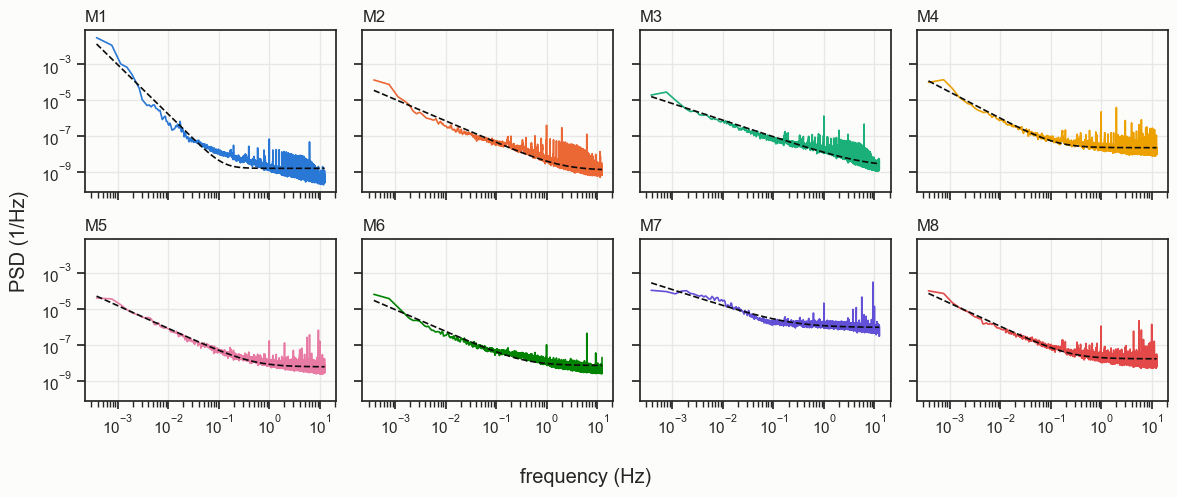

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SCOPES):
    f, p = psd[s]
    ax.loglog(f, p, color=COLORS[s])
    ax.loglog(f, 10 ** model(f, *fits[s]), color="#0b0b0b", ls="--")
    ax.set_title(s, loc="left")
for ax in axes.flat[len(SCOPES):]:
    ax.set_visible(False)
fig.supxlabel("frequency (Hz)")
fig.supylabel("PSD (1/Hz)")
fig.tight_layout()

In [14]:
def lines(f, p, n=6, above=20):
    base = 10 ** ndimage.median_filter(np.log10(p), size=301, mode="nearest")
    pk, _ = signal.find_peaks(p / base, height=above, distance=50)
    return " ".join(f"{v:.3g}" for v in np.sort(f[pk[np.argsort(p[pk] / base[pk])[::-1][:n]]]))

spec_tab = pd.DataFrame({s: {"alpha": fits[s][1], "white_pct_per_rtHz": 100 * 10 ** (fits[s][2] / 2),
                             "corner_Hz": 10 ** ((fits[s][0] - fits[s][2]) / fits[s][1]),
                             "lines_Hz": lines(*psd[s])} for s in SCOPES}).T.infer_objects()
spec_tab.round(4)

,alpha,white_pct_per_rtHz,corner_Hz,lines_Hz
M1,2.7623,0.0040,0.1233,0.999 6.25
M2,1.2002,0.0035,1.9826,0.999 2 6.25
M3,0.9284,0.0043,6.6384,0.999 2 6.25
M4,1.4691,0.0150,0.1305,1 2 3 4 5.62 6.25
M5,1.2706,0.0076,0.4845,5.62 6.25 9.38 10
M6,1.2160,0.0083,0.3668,6.25
M7,0.9033,0.0955,0.2144,5.62 9.38
M8,1.2948,0.0127,0.2499,0.999 4.37 5.62 6.25 10


**Allan deviation.** Average the signal over windows of length τ and ask how much one window's average differs
from the next. Where noise is random, longer windows average it away and the curve falls; where slow drift
takes over, longer windows see more of it and the curve rises. The minimum is the best stability the scope
reaches, and the averaging time that gives it. Read the plot from left to right: the falling part is noise,
the rising part is drift. Pure white noise falls as 1/√τ.

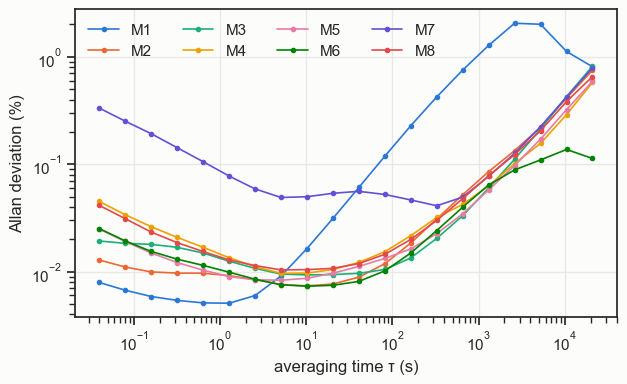

In [15]:
allan = {}
fig, ax = plt.subplots(figsize=(7, 4))
for s in SCOPES:
    r = S[s].r.to_numpy(float)
    tau, adev, _, _ = allantools.oadev(r / r.mean(), rate=FPS, data_type="freq", taus="octave")
    ax.loglog(tau, 100 * adev, color=COLORS[s], label=s, marker="o", ms=3)
    i = np.argmin(adev)
    allan[s] = {"adev_min_pct": 100 * adev[i], "adev_min_tau_s": tau[i]}
ax.set(xlabel="averaging time τ (s)", ylabel="Allan deviation (%)")
ax.legend(ncol=4)

**Autocorrelation.** How long a fluctuation lasts, after removing variations slower than 10 min (the drift).
`acf_1_over_e_s` is the lag at which the correlation falls to 1/e. A curve that drops at once is white
noise; a slow decline means fluctuations that persist for that long. Each curve is divided by its scope's
total variance, so it shows how the fluctuations are spread over time, not how large they are: a scope with a
large white-noise floor starts low. Compare sizes on the spectrum.

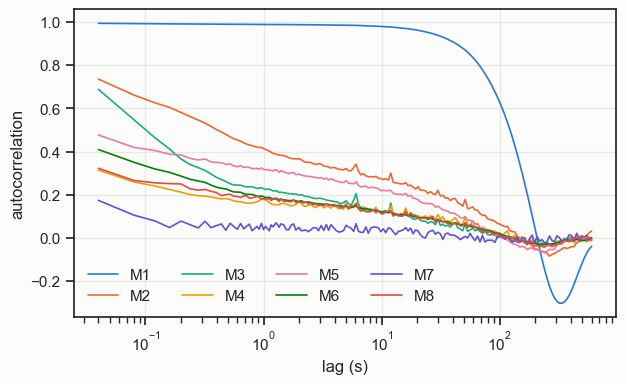

In [16]:
lags = np.unique(np.logspace(0, np.log10(600 * FPS), 200).astype(int))
acf_tab = {}
fig, ax = plt.subplots(figsize=(7, 4))
for s in SCOPES:
    r = S[s].r.reset_index(drop=True)
    x = (r - r.rolling(int(600 * FPS), center=True, min_periods=1).mean()).to_numpy()
    c = signal.correlate(x, x, mode="full", method="fft")[len(x) - 1:][: lags[-1] + 1] / (x @ x)
    ax.plot(lags / FPS, c[lags], color=COLORS[s], label=s)
    below = np.flatnonzero(c < 1 / np.e)
    acf_tab[s] = below[0] / FPS if below.size else np.nan
ax.set(xscale="log", xlabel="lag (s)", ylabel="autocorrelation")
ax.legend(ncol=4)

## Disturbances

Three kinds: **spikes** (a frame far from its 1 s running median; bursts within 1 s count once), **steps** (the
median of the next minute differs from the previous minute's), and **gaps** (more than 100 ms between frames).

In [17]:
def robust(v):
    return 1.4826 * np.median(np.abs(v - np.median(v)))

def disturbances(s, k=8):
    x = S[s].set_index("wall")
    dev = 100 * (x.r - x.r.rolling(25, center=True, min_periods=1).median()) / x.r.mean()
    hit = dev[np.abs(dev) > k * robust(dev.to_numpy())]
    burst = hit[~(hit.index.to_series().diff() <= pd.Timedelta("1s"))]
    m = x.r.resample("1s").mean().interpolate()
    step = (m.rolling(60).median().shift(-60) - m.rolling(60).median()).dropna()
    pk, _ = signal.find_peaks(np.abs(step.to_numpy()), height=k * robust(step.to_numpy()), distance=120)
    dt = np.diff(S[s].t_ns.to_numpy()) / 1e6
    gap = dt > 100
    return {"spikes": len(burst), "spike_frames_pct": 100 * len(hit) / len(x),
            "spike_median_pct": burst.median(), "steps": len(pk),
            "gaps": int(gap.sum()), "frames_missing": int((np.round(dt[gap] / 40) - 1).sum()),
            "hours": (x.index[-1] - x.index[0]).total_seconds() / 3600}, burst.index

ev_tab, spike_at = {}, {}
for s in SCOPES:
    ev_tab[s], spike_at[s] = disturbances(s)
ev_tab = pd.DataFrame.from_dict(ev_tab, orient="index")
ev_tab.insert(1, "spikes_per_h", ev_tab.spikes / ev_tab.hours)
ev_tab.drop(columns="hours").round(3)

,spikes,spikes_per_h,spike_frames_pct,spike_median_pct,steps,gaps,frames_missing
M1,0,0.000,0.000,NaN,16,8,24
M2,0,0.000,0.000,NaN,0,7,16
M3,2,0.129,0.000,-0.196,0,4,10
M4,4,0.258,0.000,-0.436,1,5,13
M5,3,0.194,0.000,-0.200,0,7,17
M6,2035,131.290,0.172,-0.197,0,6,14
M7,0,0.000,0.000,NaN,0,8,19
M8,1819,117.354,0.157,-0.226,1,3,6


Spikes per 30 min on each scope: when they happen, and whether they come in episodes.

[Text(0.5, 0.24999999999999467, ''), Text(104.75, 0.5, '')]

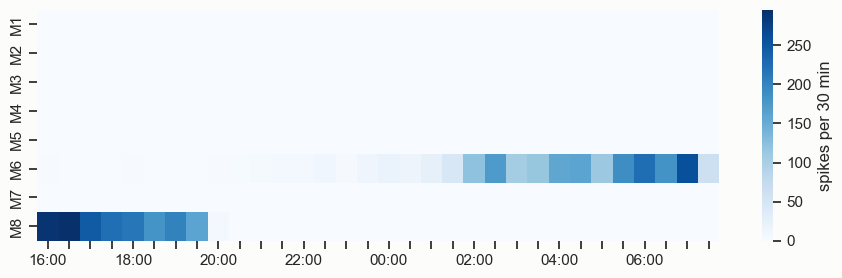

In [18]:
counts = pd.DataFrame({s: pd.Series(1, index=spike_at[s]).resample("30min").sum() for s in SCOPES}).T
counts = counts.reindex(SCOPES).fillna(0)
fig, ax = plt.subplots(figsize=(11, 3))
sns.heatmap(counts, cmap="Blues", cbar_kws={"label": "spikes per 30 min"}, ax=ax,
            xticklabels=[t.strftime("%H:%M") if i % 4 == 0 else "" for i, t in enumerate(counts.columns)])
ax.set(xlabel="", ylabel="")

What a spike looks like. Every spike on a scope is aligned on its first frame; grey lines are individual
spikes (up to 30), the coloured line is their average. The depth and width show how large and how long a
typical spike is.

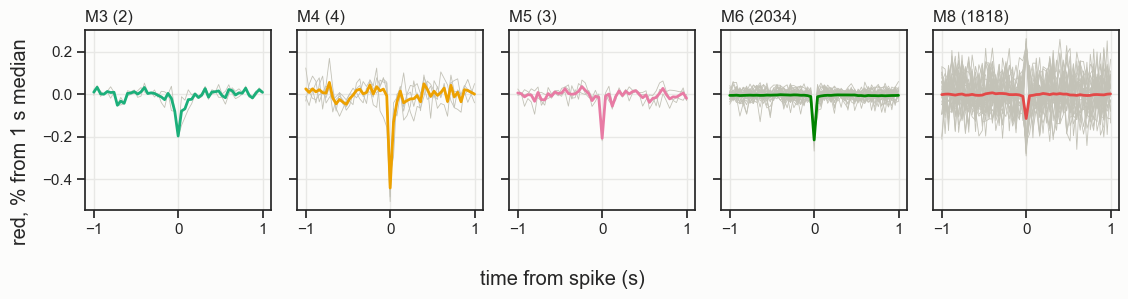

In [19]:
has = [s for s in SCOPES if len(spike_at[s])]
win = np.arange(-25, 26)                                  # one second either side, in frames
fig, axes = plt.subplots(1, len(has), figsize=(2.3 * len(has), 3), sharey=True, squeeze=False)
for ax, s in zip(axes.flat, has):
    x = S[s]
    dev = (100 * (x.r / x.r.rolling(25, center=True, min_periods=1).median() - 1)).to_numpy()
    i = np.searchsorted(x.wall.to_numpy(), spike_at[s].to_numpy())
    i = i[(i > 25) & (i < len(x) - 26)]
    seg = dev[i[:, None] + win]
    ax.plot(win / FPS, seg[:30].T, color="#c3c2b7", lw=0.6)
    ax.plot(win / FPS, seg.mean(axis=0), color=COLORS[s], lw=2)
    ax.set_title(f"{s} ({len(i)})", loc="left")
fig.supxlabel("time from spike (s)")
fig.supylabel("red, % from 1 s median")
fig.tight_layout()

Two minutes of raw 25 Hz data from the busiest half hour of each scope with more than 20 spikes. In this run
the M6 and M8 spike episodes may come from the scopes being shaken; this is not confirmed.

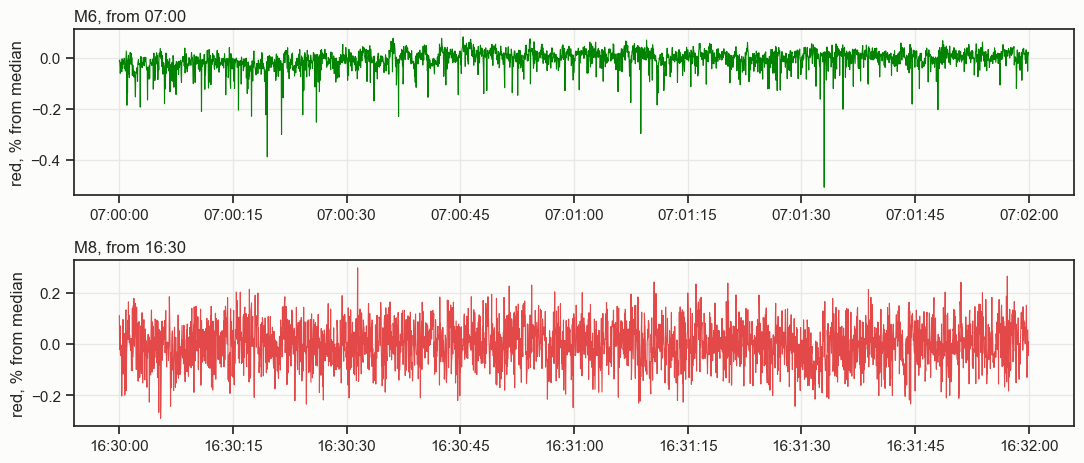

In [20]:
busy = [s for s in SCOPES if len(spike_at[s]) > 20]
fig, axes = plt.subplots(len(busy), 1, figsize=(11, 2.4 * len(busy)), squeeze=False)
for ax, s in zip(axes.flat, busy):
    t0 = counts.loc[s].idxmax()
    x = S[s][(S[s].wall >= t0) & (S[s].wall < t0 + pd.Timedelta("2min"))]
    ax.plot(x.wall, 100 * (x.r / x.r.median() - 1), color=COLORS[s], lw=0.8)
    ax.set_title(f"{s}, from {t0:%H:%M}", loc="left")
    ax.set_ylabel("red, % from median")
fig.tight_layout()

In [21]:
w, c = 2.0, counts.to_numpy()                           # coincidence window (s), spikes per 30 min
expected = sum((c[i] * c[j]).sum() for i in range(len(c)) for j in range(i + 1, len(c))) * 2 * w / 1800
allev = pd.concat([pd.Series(s, index=spike_at[s]) for s in SCOPES]).sort_index()
grp = (allev.index.to_series().diff() > pd.Timedelta(seconds=w)).cumsum()
observed = int((allev.groupby(grp.to_numpy()).nunique() >= 2).sum())
print(f"spikes on 2+ scopes within {w:.0f} s: {observed} observed, {expected:.0f} expected by chance")

spikes on 2+ scopes within 2 s: 8 observed, 7 expected by chance


## Results

In [22]:
fleet = (runs[["eid"]].join(noise_tab).join(drift_tab)
         .join(temp_tab[["std_5min_corrected_pct", "drift_corrected_pct_per_h"]])
         .join(spec_tab.drop(columns="lines_Hz")).join(pd.DataFrame(allan).T)
         .join(pd.Series(acf_tab, name="acf_1_over_e_s"))
         .join(ev_tab[["spikes_per_h", "steps", "gaps"]]))
fleet = fleet.reindex(SCOPES)
os.makedirs(OUT, exist_ok=True)
fleet.to_csv(f"{OUT}/led_cam_intensity_fluctuations.csv")
for s, row in fleet.iterrows():                           # one copy next to each run's data
    with open(os.path.join(exps.get_analysis_dir(row.eid), "led_cam_intensity_fluctuations.yaml"), "w") as f:
        yaml.safe_dump({k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}, f)
fleet.round(4)

,eid,r_mean,cv_pct,floor_pct,g_dark,b_dark,drift_pct_per_h,last_vs_first_h_pct,tempco_pct_per_C,corr_with_temp,...,drift_corrected_pct_per_h,alpha,white_pct_per_rtHz,corner_Hz,adev_min_pct,adev_min_tau_s,acf_1_over_e_s,spikes_per_h,steps,gaps
scope,,,,,,,,,,,,,,,,,,,,,
M1,2aa777b229,178.9904,4.3929,0.0079,0.4503,0.3120,-0.4720,-14.0481,7.7166,0.5723,...,0.0845,2.7623,0.0040,0.1233,0.0051,1.28,144.04,0.0000,16,8
M2,9341ba14b4,93.6416,0.8697,0.0128,0.0489,0.0175,0.1895,2.8891,-2.5530,-0.9221,...,0.0146,1.2002,0.0035,1.9826,0.0074,10.24,1.80,0.0000,0,7
M3,54f25f62bc,70.7434,0.9116,0.0193,0.0747,0.0362,0.2029,3.0626,-2.7520,-0.9713,...,0.0085,0.9284,0.0043,6.6384,0.0093,10.24,0.20,0.1290,0,4
M4,d794c6fc7a,65.7450,0.6329,0.0450,0.0412,0.0156,0.1369,2.1316,-1.8207,-0.9897,...,0.0003,1.4691,0.0150,0.1305,0.0096,5.12,0.04,0.2581,1,5
M5,a227253e5d,87.8808,0.7192,0.0249,0.0472,0.0180,0.1595,2.5798,-1.9668,-0.9824,...,0.0050,1.2706,0.0076,0.4845,0.0083,5.12,0.28,0.1935,0,7
M6,4231d6c2d5,79.3505,0.1881,0.0252,0.0446,0.0175,0.0017,0.5181,-0.0595,-0.1048,...,-0.0026,1.2160,0.0083,0.3668,0.0073,10.24,0.08,131.2899,0,6
M7,7bf3efeea8,76.9537,0.9941,0.3330,0.0437,0.0167,0.2012,3.2625,-2.5375,-0.9962,...,0.0000,0.9033,0.0955,0.2144,0.0411,327.68,0.04,0.0000,0,8
M8,15644047a0,69.3451,0.8085,0.0413,0.0393,0.0143,0.1766,2.8435,-2.1664,-0.9899,...,0.0015,1.2948,0.0127,0.2499,0.0104,5.12,0.04,117.3538,1,3


## Acceptance

None. This calibration characterises each scope and writes nothing to it, so there is no pass or fail.

## Persistent records

This calibration writes 0 records to the scope.